In [1]:
import os
import sys
import time
import pickle
import warnings
warnings.filterwarnings("ignore")
sys.path.append("/path/to/GeneSPOT")

from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
from tqdm import tqdm
import spatialdata as sd
import spatialdata_plot
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['font.family'] = 'Aptos'
matplotlib.rcParams['pdf.fonttype'] = 42

In [2]:
%load_ext autoreload
%autoreload 2

from genespot.utils import seed_everything, filter_extreme_values
from vendor.niche_embedding.MENDER import Mender
from genespot.preprocess import preprocess_adata, concat_features
from genespot.genespot import build_graph, topk_similar
from genespot.optimal_transports import cal_ot_distance
from genespot.graph_representation import node2vec
from genespot.visualization import create_cmap
from genespot.visualization import create_cmap, soview

random_state = 42
seed_everything(random_state)

cmap_r = create_cmap(['white', 'red'])
cmap_g = create_cmap(['white', 'green'])
cmap_b = create_cmap(['white', 'blue'])
cmap_rbgs = [cmap_r, cmap_g, cmap_b]

In [35]:
DATA_DIR = Path('/path/to/GeneSPOT/data/xenium_hbc')
RES_DIR = Path('/path/to/GeneSPOT/reproduce/supp/res')
OUTPUTS_DIR = Path('/path/to/GeneSPOT/reproduce/supp/outputs')

os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

In [4]:
rep1_adata = sc.read_h5ad(DATA_DIR / 'rep1_adata.h5ad')
genes = rep1_adata.var_names.tolist()

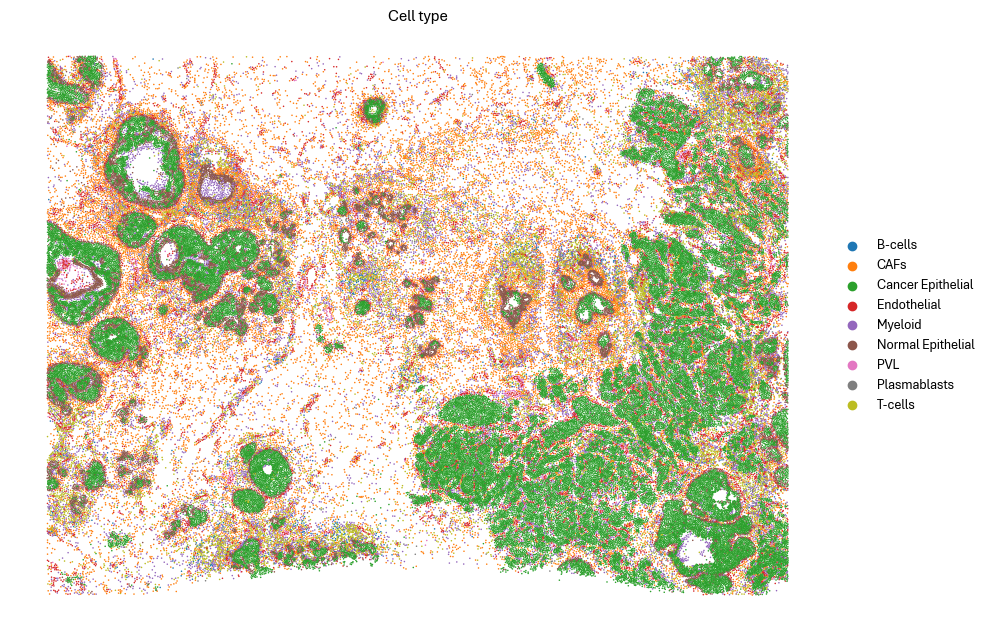

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
sc.pl.embedding(rep1_adata, basis='spatial', color='celltype_major', size=5, show=False, ax=ax, frameon=False)
ax.set_title('Cell type')

ax.invert_xaxis()
ax.set_aspect(1)
plt.tight_layout()
plt.show()

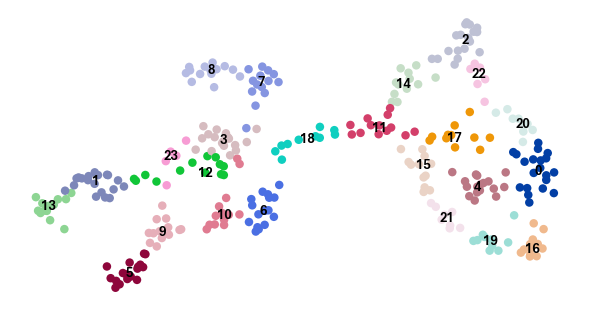

In [6]:
gdata = sc.read_h5ad(RES_DIR / 'gdata_cellcharter.h5ad')
ffsitance = gdata.uns['ffdistance']
sc.tl.leiden(gdata, resolution=5, random_state=random_state)

fig, ax = plt.subplots(1, 1, figsize=(6, 6))

sc.pl.umap(gdata, color='leiden', 
    size=150, ax=ax, show=False, legend_loc='on data', frameon=False
)
ax.set_title('')
ax.set_aspect(1)

plt.tight_layout()
plt.show()

In [7]:
rep1_adata.var['GeneSPOT_GC'] = gdata[genes].obs['leiden']
n_gcs = len(np.unique(rep1_adata.var['GeneSPOT_GC']))
agged_gc = sc.get.aggregate(rep1_adata, by='GeneSPOT_GC', func='mean', axis=1)[:, [str(gc) for gc in range(n_gcs)]].layers['mean']
rep1_adata.obs[[f'GeneSPOT_GC{gc}' for gc in range(n_gcs)]] = np.array(agged_gc)

In [8]:
stminer_gene_labels = pd.read_csv(RES_DIR / 'stminer_cluster' / 'stminer_genes_labels.csv', index_col=0)
stminer_gene_labels = stminer_gene_labels.set_index('gene_id')
rep1_adata.var['STMiner_GC'] = stminer_gene_labels.loc[rep1_adata.var_names, 'labels']

stminer_n_gcs = len(np.unique(rep1_adata.var['STMiner_GC']))
agged_gc = sc.get.aggregate(rep1_adata, by='STMiner_GC', func='mean', axis=1)[:, [str(gc) for gc in range(n_gcs)]].layers['mean']
rep1_adata.obs[[f'STMiner_GC{gc}' for gc in range(n_gcs)]] = np.array(agged_gc)

In [9]:
genespot_gcs_dict = dict()
stminer_gcs_dict = dict()
print("GeneSPOT".center(100, "="))
for gc in range(n_gcs):
    gcgs = rep1_adata.var_names[rep1_adata.var['GeneSPOT_GC'] == str(gc)].tolist()
    genespot_gcs_dict[gc] = gcgs
    print(f'GC{gc}', ','.join(gcgs))

==============================================GeneSPOT==============================================
GC0 ANKRD30A,C6orf132,CD9,CDH1,DMKN,ELF3,EPCAM,GATA3,HPX,KLF5,KRT7,KRT8,LYPD3,MLPH,OCIAD2,RTKN2,SCD,SH3YL1,SLC5A6,TFAP2A
GC1 CD247,CD3D,CD3E,CD3G,CD69,CTLA4,CYTIP,GPR183,GZMA,IL2RG,IL7R,KLRB1,LILRA4,PDCD1,PDCD1LG2,PTPRC,SLAMF1,SPIB,TRAC
GC2 C15orf48,C5orf46,KIT,KRT14,KRT15,KRT16,KRT23,KRT5,KRT6B,MMP12,MYH11,OPRPN,PIGR,PTN,S100A8,SCGB2A1,SERPINA3,SFRP1
GC3 ANGPT2,ANKRD29,C1QC,CD68,CD8A,CLIC6,FCER1G,FCGR3A,IGSF6,ITM2C,KLRC1,KLRD1,LUM,LY86,MMRN2,PDE4A,PDK4,SSTR2
GC4 ADAM9,CCDC6,CCND1,CTTN,DAPK3,ERBB2,HDC,LARS,NARS,QARS,RHOH,RORC,SEC24A,SMS,SRPK1,TMEM147,ZNF562
GC5 ADH1B,ADIPOQ,CCL8,CLDN5,CTSG,DPT,EDNRB,FBLN1,FCER1A,GZMB,GZMK,IGF1,IL2RA,LEP,MEDAG,MRC1,SFRP4
GC6 ADGRE5,AQP1,CAV1,CD1C,CD274,CLEC9A,CLECL1,CX3CR1,FBLIM1,FGL2,GLIPR1,MNDA,PLD4,S100A4,SLAMF7,TCF7
GC7 BASP1,CXCR4,CYP1A1,DUSP2,ERN1,ESM1,FOXP3,LAG3,MPO,MUC6,NDUFA4L2,PELI1,PPARG,SNAI1
GC8 AVPR1A,BTNL9,CD93,CLEC14A,EGFL7,HOXD9,IL3RA,KD

In [10]:
print("STMiner".center(100, "="))
for gc in range(n_gcs):
    gcgs = rep1_adata.var_names[rep1_adata.var['STMiner_GC'] == gc].tolist()
    stminer_gcs_dict[gc] = gcgs
    print(f'GC{gc}', ','.join(gcgs))

==============================================STMiner===============================================
GC0 ANGPT2,ANKRD29,AVPR1A,CAV1,CLEC14A,HOXD9,IL3RA,KDR,MMRN2,PDK4,PPARG,RAMP2,VWF
GC1 APOBEC3B,CCL20,CCL5,CD80,CD83,CD86,CXCR4,ERN1,FCER1G,FCGR3A,HAVCR2,IGSF6,ITGAX,MNDA,PIM1,SMAP2
GC2 ACTA2,BACE2,DNAAF1,DUSP5,MYBPC1,TMEM147
GC3 AHSP,BANK1,CD19,CD79B,DUSP2,GZMK,LTB,PDCD1,PLD4
GC4 APOC1,CCND1,CXCL16,DNTTIP1,ERBB2,LARS,LGALSL,POLR2J3,PTRHD1,QARS,RORC,SEC11C,SEC24A,SQLE,SRPK1,TACSTD2,TPD52,TRIB1
GC5 C5orf46,KRT14,KRT16,KRT23,KRT5,KRT6B
GC6 APOBEC3A,CRISPLD2,FBLIM1,LRRC15,MMP2,MYLK,PCOLCE,PDGFRA,PDGFRB,POSTN,SSTR2,TCEAL7,TCF4,ZEB1
GC7 CCR7,CD247,CD27,CD69,CD79A,CLECL1,GPR183,IL2RG,IL7R,KLRB1,MS4A1,PDCD1LG2,PTGDS,PTPRC,SELL,SPIB,TCF7,TIGIT,TRAC
GC8 ADH1B,AKR1C3,CD93,CXCL12,DPT,FCER1A,IGF1,IL2RA,MEDAG,MRC1
GC9 AKR1C1,AQP1,BTNL9,CCL8,CSF3,CTSG,CYP1A1,EDNRB,LPL,MMP12,MUC6,PGR,SOX17,TAC1,UCP1
GC10 C15orf48,CLCA2,FOXC2,MMP1,S100A8
GC11 ABCC11,AR,CENPF,DMKN,EIF4EBP1,ENAH,EPCAM,ESM1,HMGA1,HPX,KLF5,

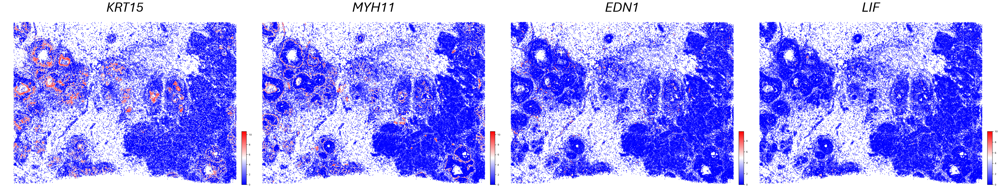

In [11]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 4, figsize=(40, 10))
selected_genes = ['KRT15', 'MYH11', 'EDN1', 'LIF']

for i, gene in enumerate(selected_genes):
    ax = axs[i]
    sc.pl.embedding(rep1_adata, basis='spatial', color=gene, size=10, show=False, 
                    ax=ax, frameon=False,
                    cmap='bwr', colorbar_loc=None)
    ax.set_title(gene, fontdict={'fontstyle': 'italic', 'fontsize': 40})
    ax.invert_xaxis()
    ax.set_aspect(1)

    images = [obj for obj in ax.get_children() if hasattr(obj, 'get_cmap')]
    if images:
        axins = inset_axes(ax, width="2%", height="30%", loc='lower right',
                          bbox_to_anchor=(0.01, 0.02, 1, 1), bbox_transform=ax.transAxes,
                          borderpad=1)
        cbar = plt.colorbar(images[0], cax=axins, orientation='vertical')
        cbar.ax.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

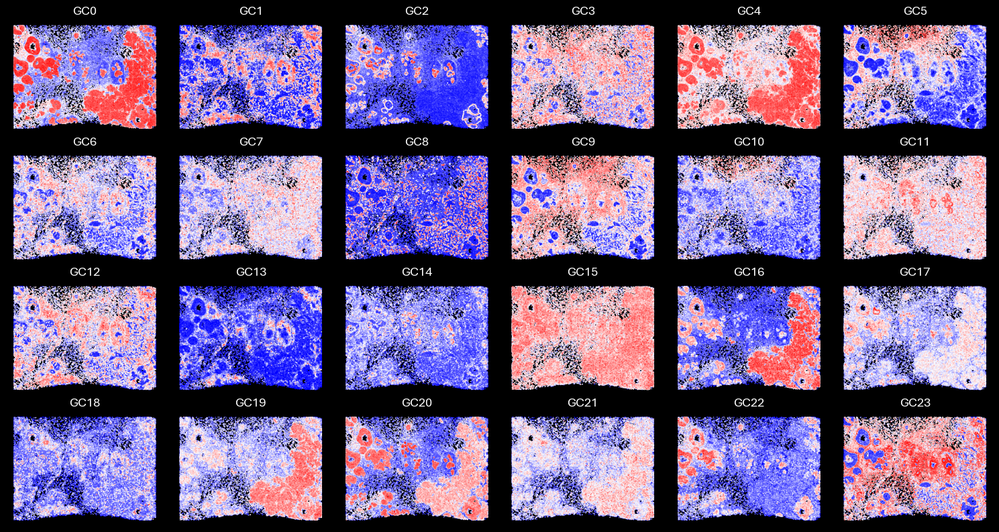

In [12]:
n_cols = 6
n_rows = (n_gcs + n_cols - 1) // n_cols
fig = plt.figure(figsize=(n_cols*2.5, n_rows*2), facecolor='black')

for i, gc in enumerate(range(n_gcs)):
    ax = fig.add_subplot((n_gcs + n_cols - 1) // n_cols, n_cols, i + 1)
    sc.pl.embedding(rep1_adata, basis='spatial', color=f'GeneSPOT_GC{gc}', size=5, show=False, ax=ax, colorbar_loc=None, cmap='bwr', frameon=False)
    ax.set_title(f'GC{gc}', color='white', fontsize=14)
    ax.invert_xaxis()
    ax.set_aspect(1)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('white')
        spine.set_linewidth(2)

plt.tight_layout()
plt.show()

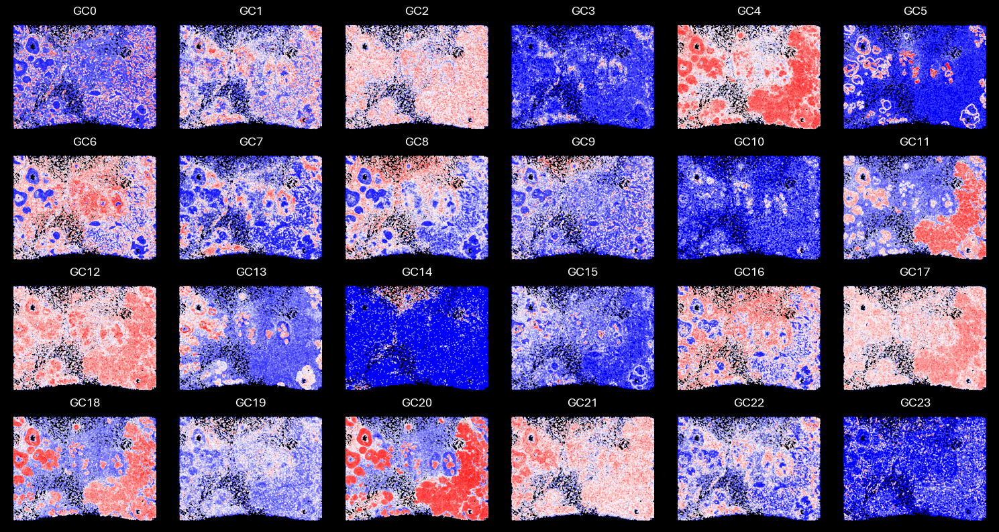

In [13]:
n_cols = 6
n_rows = (n_gcs + n_cols - 1) // n_cols
fig = plt.figure(figsize=(n_cols*2.5, n_rows*2), facecolor='black')

for i, gc in enumerate(range(n_gcs)):
    ax = fig.add_subplot((n_gcs + n_cols - 1) // n_cols, n_cols, i + 1)
    sc.pl.embedding(rep1_adata, basis='spatial', color=f'STMiner_GC{gc}', size=5, show=False, ax=ax, colorbar_loc=None, cmap='bwr', frameon=False)
    ax.set_title(f'GC{gc}', color='white', fontsize=14)
    ax.invert_xaxis()
    ax.set_aspect(1)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('white')
        spine.set_linewidth(2)

plt.tight_layout()
plt.show()

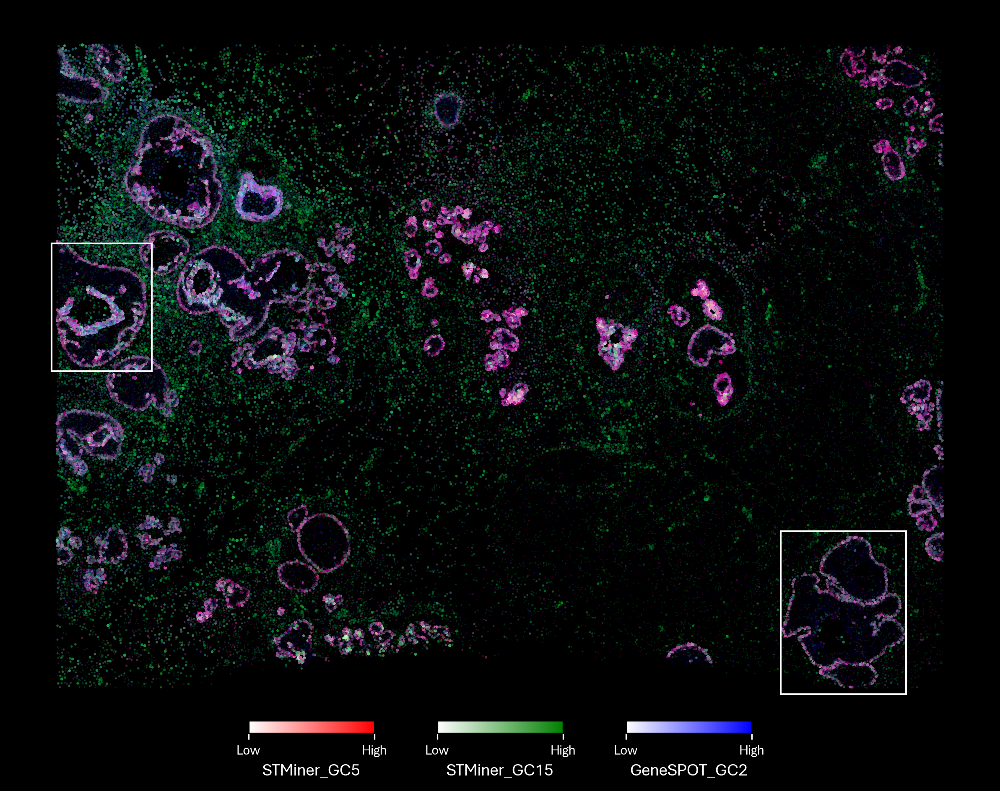

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10), dpi=300)

channels = ['STMiner_GC5', 'STMiner_GC15', 'GeneSPOT_GC2']
soview(
    rep1_adata,
    r=channels[0],
    g=channels[1],
    b=channels[2],
    ax=ax, size_factor=5, frameon=False, facecolor='black'
)
ax.set_aspect(1)
ax.invert_xaxis()

from matplotlib.patches import Rectangle
box_width = 5000
box_height = 6500
box_x = 1500
box_y = -200
rect = Rectangle((box_x, box_y), box_width, box_height, 
                 linewidth=1, edgecolor='white', facecolor='none')
ax.add_patch(rect)


box_width = 4000
box_height = 5100
box_x = 31600
box_y = 12700
rect = Rectangle((box_x, box_y), box_width, box_height, 
                 linewidth=1, edgecolor='white', facecolor='none')
ax.add_patch(rect)


ax_pos = ax.get_position()

cbar_width = 0.1
cbar_height = 0.01
cbar_spacing = 0.05
cbar_bottom = ax_pos.y0 - 0.01

num_channels = len(channels)
total_width = num_channels * cbar_width + (num_channels - 1) * cbar_spacing
left_start = ax_pos.x0 + (ax_pos.width - total_width) / 2
cbar_axs = []
for i in range(num_channels):
    left = left_start + i * (cbar_width + cbar_spacing)
    cbar_axs.append(fig.add_axes([left, cbar_bottom, cbar_width, cbar_height]))

for i, (cbar, cmap) in enumerate(zip(cbar_axs, cmap_rbgs)):
    cb = plt.colorbar(plt.cm.ScalarMappable(cmap=cmap), 
                      cax=cbar, orientation='horizontal')
    cb.set_label(f'{channels[i]}', fontsize=10)
    cb.ax.xaxis.label.set_color('white')
    cb.ax.tick_params(colors='white', labelsize=8)
    cb.set_ticks([0, 1])
    cb.set_ticklabels(['Low', 'High'])

plt.show()

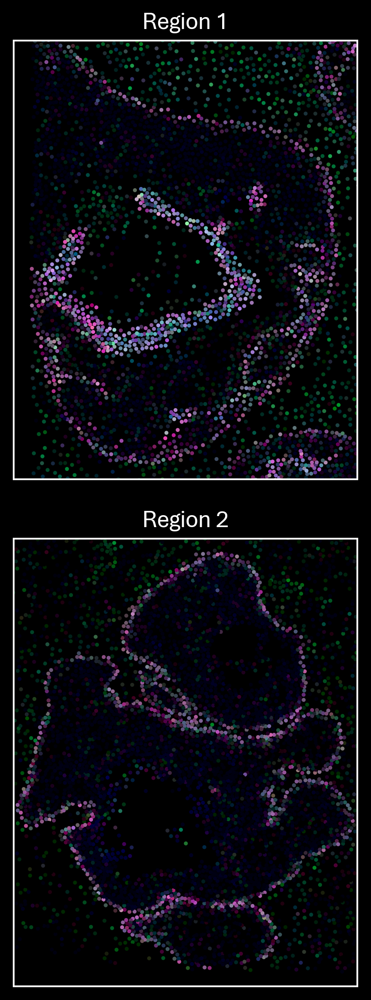

In [15]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(2, 1, figsize=(3, 8), dpi=300, facecolor='black')

regions = [
    {'box_x': 31600, 'box_y': 12700, 'box_width': 4000, 'box_height': 5100, 'title': 'Region 1'},
    {'box_x': 1500, 'box_y': -200, 'box_width': 5000, 'box_height': 6500, 'title': 'Region 2'},
]

for idx, (ax, region) in enumerate(zip(axes, regions)):
    soview(
        rep1_adata,
        r=channels[0],
        g=channels[1],
        b=channels[2],
        ax=ax, 
        s=5,
        size_factor=None,
        frameon=False, facecolor='black'
    )
    ax.set_aspect(1)
    ax.invert_xaxis()
    
    box_x = region['box_x']
    box_y = region['box_y']
    box_width = region['box_width']
    box_height = region['box_height']
    
    ax.set_xlim(box_x + box_width, box_x)
    ax.set_ylim(box_y, box_y + box_height)
    
    rect = Rectangle((box_x, box_y), box_width, box_height, 
                     linewidth=2, edgecolor='white', facecolor='none')
    ax.add_patch(rect)
    
    ax.set_title(region['title'], color='white', fontsize=14)
    ax.set_facecolor('black')
    
    ax.tick_params(colors='white', labelsize=8)

    for spine in ax.spines.values():
        spine.set_color('white')

plt.tight_layout()
plt.show()

In [27]:
import gseapy as gp
import textwrap


gene_sets = [
    'GO_Biological_Process_2025',
]

results = []



for gc, genes in zip(
    ['GeneSPOT_GC2', 'STMiner_GC5', 'STMiner_GC15'],
    [genespot_gcs_dict[2], stminer_gcs_dict[5], stminer_gcs_dict[15]]
):
    enr = gp.enrichr(
        gene_list=genes,
        gene_sets=gene_sets,
        outdir=None,
        verbose=True)
    genepsot_results = enr.results
    genepsot_results['Term'] = genepsot_results['Term'].str.split('(').str[0]
    genepsot_results['Group'] = gc

    results.append(genepsot_results)
    
results = pd.concat(results)

2026-02-15 13:40:18,535 [INFO] Run: GO_Biological_Process_2025 
2026-02-15 13:40:21,385 [INFO] Done.
2026-02-15 13:40:23,013 [INFO] Run: GO_Biological_Process_2025 
2026-02-15 13:40:25,404 [INFO] Done.
2026-02-15 13:40:27,027 [INFO] Run: GO_Biological_Process_2025 
2026-02-15 13:40:29,858 [INFO] Done.


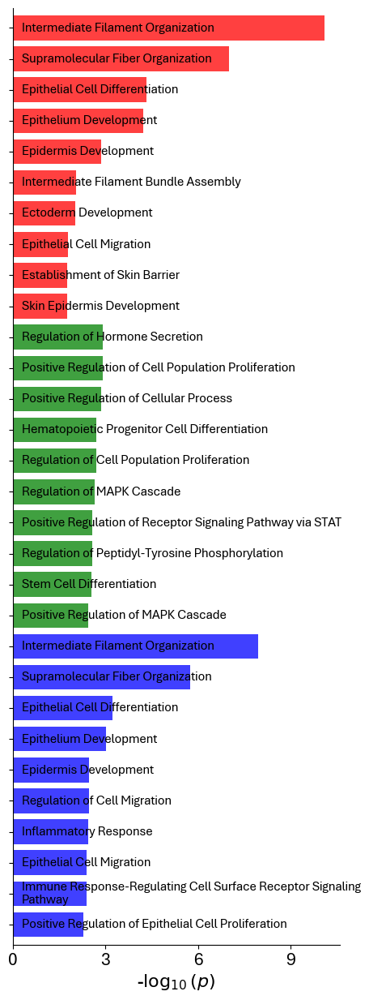

In [ ]:
ax = gp.barplot(
    results, 
    group='Group',
    x='Adjusted P-value',
    cutoff=0.05,
    color={'STMiner_GC5': 'red', 'STMiner_GC15': 'green', 'GeneSPOT_GC2': 'blue'},
    figsize=(15, 15),
    top_term=10,
    title_fontsize=6,
    width=0.8
)
ax.set_xlabel(r'-$\log_{10}(p)$')
ax.get_legend().remove()

bars = ax.patches
yticklabels = [label.get_text() for label in ax.get_yticklabels()]
max_width = 60
import textwrap
for bar, label in zip(bars, yticklabels):
    wrapped_term = '\n'.join(textwrap.wrap(label, max_width))
    ax.text(
        0.3,
        bar.get_y() + bar.get_height() / 2,
        wrapped_term,
        va='center',
        ha='left',
        fontsize=12
    )
ax.set_yticklabels(['' for _ in ax.get_yticklabels()])
ax.set_aspect(1)
plt.savefig(OUTPUTS_DIR / 'enrichr_barplot_S11E.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

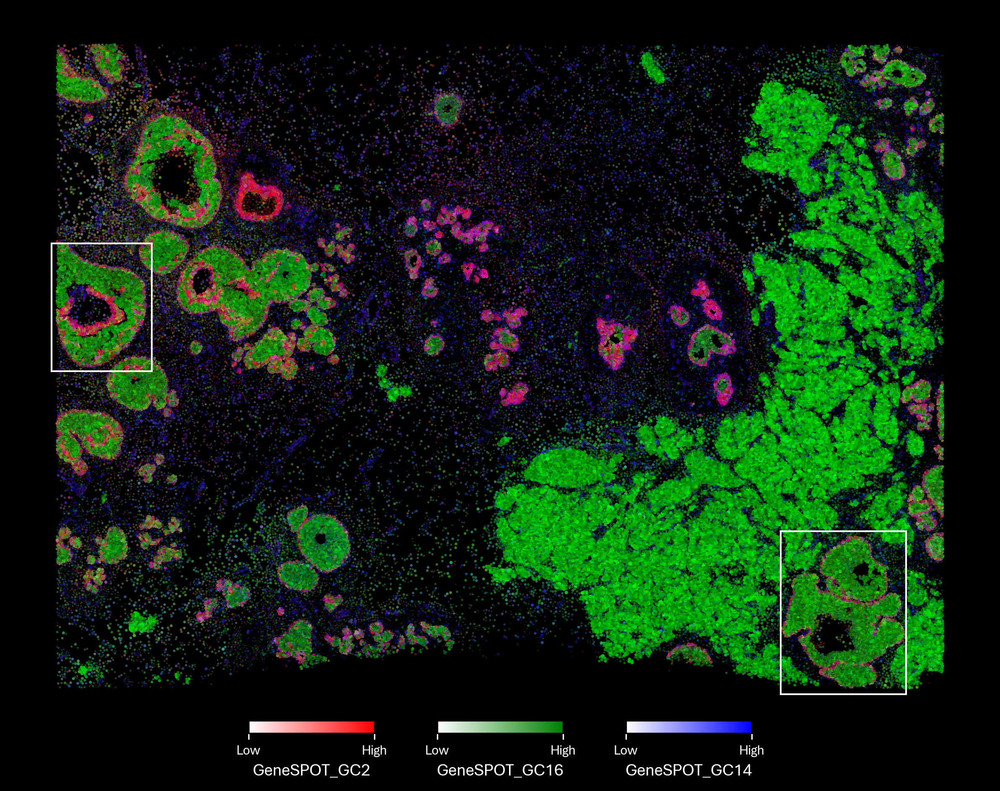

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10), dpi=300)

channels = ['GeneSPOT_GC2', 'GeneSPOT_GC16', 'GeneSPOT_GC14']
soview(
    rep1_adata,
    r=channels[0],
    g=channels[1],
    b=channels[2],
    ax=ax, size_factor=5, frameon=False, facecolor='black'
)
ax.set_aspect(1)
ax.invert_xaxis()

from matplotlib.patches import Rectangle
box_width = 5000
box_height = 6500
box_x = 1500
box_y = -200
rect = Rectangle((box_x, box_y), box_width, box_height, 
                 linewidth=1, edgecolor='white', facecolor='none')
ax.add_patch(rect)


box_width = 4000
box_height = 5100
box_x = 31600
box_y = 12700
rect = Rectangle((box_x, box_y), box_width, box_height, 
                 linewidth=1, edgecolor='white', facecolor='none')
ax.add_patch(rect)


ax_pos = ax.get_position()

cbar_width = 0.1
cbar_height = 0.01
cbar_spacing = 0.05
cbar_bottom = ax_pos.y0 - 0.01

num_channels = len(channels)
total_width = num_channels * cbar_width + (num_channels - 1) * cbar_spacing
left_start = ax_pos.x0 + (ax_pos.width - total_width) / 2
cbar_axs = []
for i in range(num_channels):
    left = left_start + i * (cbar_width + cbar_spacing)
    cbar_axs.append(fig.add_axes([left, cbar_bottom, cbar_width, cbar_height]))

for i, (cbar, cmap) in enumerate(zip(cbar_axs, cmap_rbgs)):
    cb = plt.colorbar(plt.cm.ScalarMappable(cmap=cmap), 
                      cax=cbar, orientation='horizontal')
    cb.set_label(f'{channels[i]}', fontsize=10)
    cb.ax.xaxis.label.set_color('white')
    cb.ax.tick_params(colors='white', labelsize=8)
    cb.set_ticks([0, 1])
    cb.set_ticklabels(['Low', 'High'])

plt.show()

In [37]:
selected_gcs = [2, 16, 14]
gene_sets = [
    'GO_Biological_Process_2025',
]

results = []
for gc in selected_gcs:
    genes = genespot_gcs_dict[gc]

    enr = gp.enrichr(
        gene_list=genes,
        gene_sets=gene_sets,
        outdir=None,
        verbose=True)
    genepsot_results = enr.results
    genepsot_results['Term'] = genepsot_results['Term'].str.split('(').str[0]
    genepsot_results['Group'] = f'GeneSPOT_GC{gc}'

    results.append(genepsot_results)

results = pd.concat(results)

2026-02-15 13:54:33,530 [INFO] Run: GO_Biological_Process_2025 
2026-02-15 13:54:36,393 [INFO] Done.
2026-02-15 13:54:38,018 [INFO] Run: GO_Biological_Process_2025 
2026-02-15 13:54:40,631 [INFO] Done.
2026-02-15 13:54:42,283 [INFO] Run: GO_Biological_Process_2025 
2026-02-15 13:54:45,135 [INFO] Done.


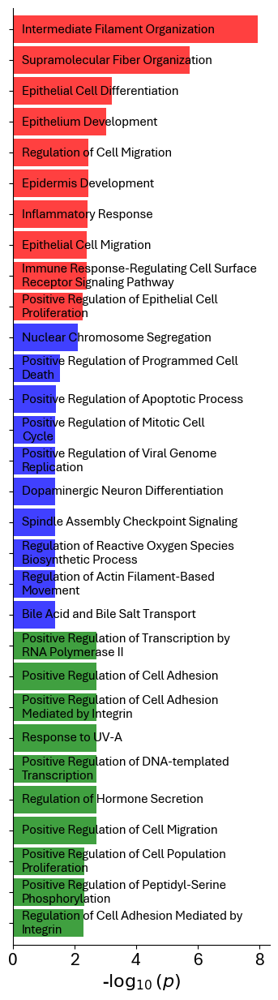

In [38]:
ax = gp.barplot(
    results, 
    group='Group',
    x='Adjusted P-value',
    cutoff=0.05,
    color={'GeneSPOT_GC2': 'red', 'GeneSPOT_GC16': 'blue', 'GeneSPOT_GC14': 'green'},
    figsize=(15, 15),
    top_term=10,
    title_fontsize=6,
    width=0.9
)
ax.set_xlabel(r'-$\log_{10}(p)$')

# 不显示legend
ax.get_legend().remove()

# 在bar上显示yticklabels
bars = ax.patches
yticklabels = [label.get_text() for label in ax.get_yticklabels()]
max_width = 40
import textwrap
for bar, label in zip(bars, yticklabels):
    wrapped_term = '\n'.join(textwrap.wrap(label, max_width))
    ax.text(
        0.3,
        bar.get_y() + bar.get_height() / 2,
        wrapped_term,
        va='center',
        ha='left',
        fontsize=12  # 用于对应 set_ylabel 的fontsize
    )
ax.set_yticklabels(['' for _ in ax.get_yticklabels()])

ax.set_aspect(1)
plt.savefig(OUTPUTS_DIR / 'enrichr_barplot_S15B.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()